In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report

In [3]:
import os
data_path = 'creditcard.csv' if os.path.exists('creditcard.csv') else (r'archive/creditcard.csv' if os.path.exists('archive/creditcard.csv') else 'creditcard.csv')
df = pd.read_csv(data_path)
print(df.head(15))

    Time        V1        V2        V3        V4        V5        V6   
0    0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  \
1    0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361   
2    1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499   
3    1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203   
4    2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921   
5    2.0 -0.425966  0.960523  1.141109 -0.168252  0.420987 -0.029728   
6    4.0  1.229658  0.141004  0.045371  1.202613  0.191881  0.272708   
7    7.0 -0.644269  1.417964  1.074380 -0.492199  0.948934  0.428118   
8    7.0 -0.894286  0.286157 -0.113192 -0.271526  2.669599  3.721818   
9    9.0 -0.338262  1.119593  1.044367 -0.222187  0.499361 -0.246761   
10  10.0  1.449044 -1.176339  0.913860 -1.375667 -1.971383 -0.629152   
11  10.0  0.384978  0.616109 -0.874300 -0.094019  2.924584  3.317027   
12  10.0  1.249999 -1.221637  0.383930 -1.234899 -1.485419 -0.75

In [4]:
df.shape

(284807, 31)

In [5]:
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [6]:
print(df["Class"].value_counts())

Class
0    284315
1       492
Name: count, dtype: int64


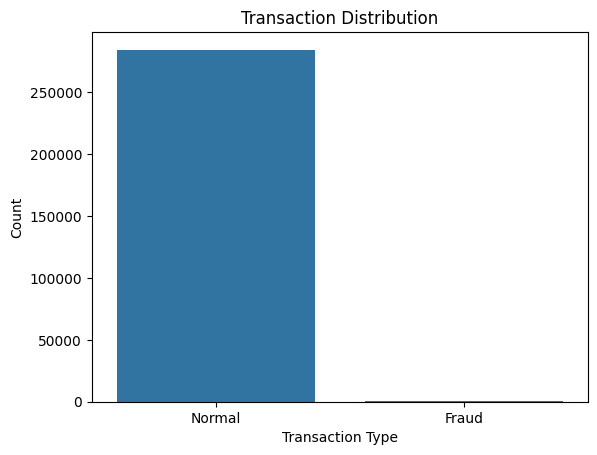

In [7]:
sns.countplot(x='Class',data=df)
plt.xticks([0,1], ["Normal", "Fraud"])
plt.xlabel("Transaction Type")
plt.ylabel("Count")
plt.title("Transaction Distribution")
plt.show()

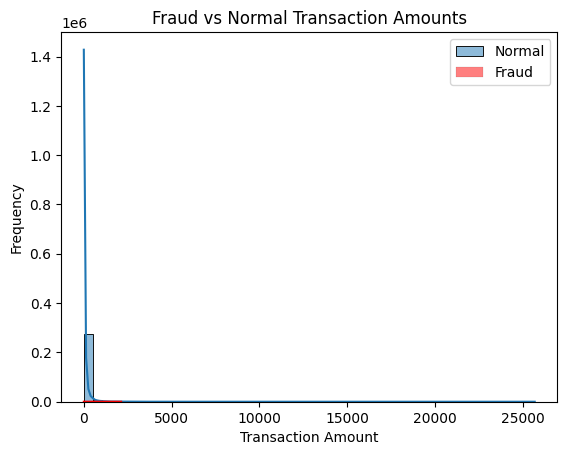

In [8]:
sns.histplot(df[df["Class"]==0]["Amount"],bins=50,alpha=0.5,label='Normal',kde=True)
sns.histplot(df[df["Class"]==1]["Amount"],bins=50,alpha=0.5,color='red',label='Fraud',kde=True)
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.title("Fraud vs Normal Transaction Amounts")
plt.legend()
plt.show()

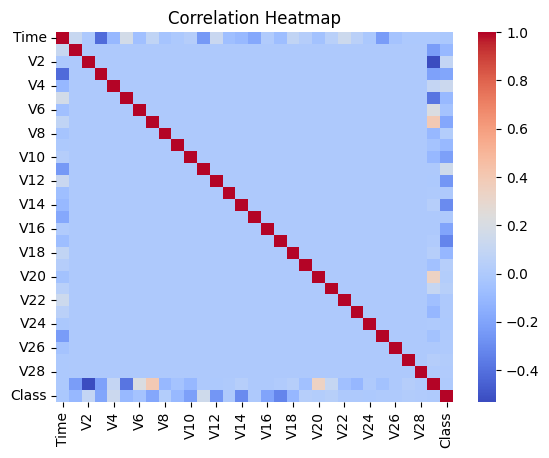

In [9]:
sns.heatmap(df.corr(),cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

In [12]:
X=df.drop("Class",axis=1)
y=df["Class"]
print(X.shape)
print(y.shape)

(284807, 30)
(284807,)


In [13]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
rf = RandomForestClassifier(random_state=42,n_jobs=-1)
rf.fit(X_train, y_train)

RandomForestClassifier(n_jobs=-1, random_state=42)

In [16]:
y_pred = rf.predict(X_test)

print("\nBASELINE MODEL PERFORMANCE\n")

print("Accuracy :", round(
    accuracy_score(y_test, y_pred),4))

print("Precision:", round(
    precision_score(y_test, y_pred),4))

print("Recall   :", round(
    recall_score(y_test, y_pred),4))

print("F1 Score :", round(
    f1_score(y_test, y_pred),4))


BASELINE MODEL PERFORMANCE

Accuracy : 0.9996
Precision: 0.9412
Recall   : 0.8163
F1 Score : 0.8743


In [17]:
cm = confusion_matrix(y_test, y_pred)

print("CONFUSION MATRIX\n")

print(cm)

CONFUSION MATRIX

[[56859     5]
 [   18    80]]


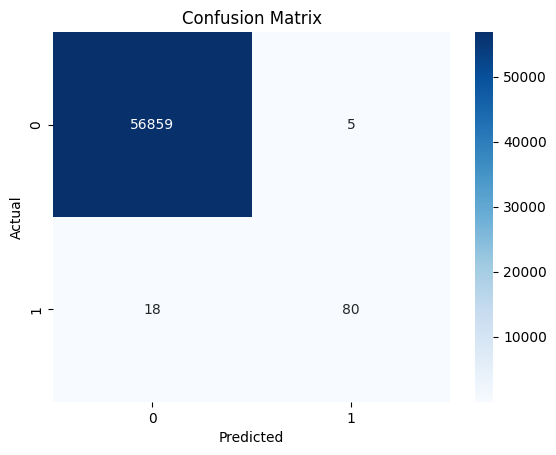

In [18]:
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues')

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("Confusion Matrix")

plt.show()

In [19]:
cr = classification_report(y_test,y_pred)

print("\nCLASSIFICATION REPORT\n")

print(cr)


CLASSIFICATION REPORT

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.94      0.82      0.87        98

    accuracy                           1.00     56962
   macro avg       0.97      0.91      0.94     56962
weighted avg       1.00      1.00      1.00     56962



In [20]:
sample_df = X_test.copy()

sample_df["Actual"] = y_test.values

sample_df["Predicted"] = y_pred

print("\nSAMPLE PREDICTIONS\n")

print(sample_df.head(15).reset_index(drop=True))


SAMPLE PREDICTIONS

        Time        V1        V2        V3        V4        V5        V6   
0   160760.0 -0.674466  1.408105 -1.110622 -1.328366  1.388996 -1.308439  \
1    19847.0 -2.829816 -2.765149  2.537793 -1.074580  2.842559 -2.153536   
2    88326.0 -3.576495  2.318422  1.306985  3.263665  1.127818  2.865246   
3   141734.0  2.060386 -0.015382 -1.082544  0.386019 -0.024331 -1.074935   
4    38741.0  1.209965  1.384303 -1.343531  1.763636  0.662351 -2.113384   
5   151934.0 -0.345588  1.070328 -0.652790 -0.492207  0.749482 -0.949391   
6   159122.0 -0.864273  0.361412 -0.346667 -1.938227 -1.065839 -1.056202   
7    41656.0 -1.679000  0.004724  2.093100 -0.209994  1.112123 -1.254060   
8    52202.0 -0.806445  0.865983  1.105898  1.383957 -0.018110  0.140882   
9    52081.0  1.169646 -0.823924  0.467031 -0.840968 -0.850688  0.062139   
10   59813.0 -3.502600  2.730569 -0.962733  1.496190 -7.251700  6.702511   
11   22644.0 -0.518531  1.062806  2.053490  3.150431 -1.129058  0.5